In [7]:
# from google.colab import drive
from pathlib import Path
from collections import Counter  # Counts the number of images in each class.
import json  # Saves the train/validation/test manifest in a readable format.
import os  # Reads environment variables so paths work on Kaggle and Vast.ai.
import time  # Measures how long each training stage takes.
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)
import mlflow

In [8]:
# drive.mount('/content/drive')
# DATA_PATH = Path("/content/drive/MyDrive/NeuroVisionAI/raw/Data")

# Select the usual Kaggle path when available; Vast.ai can use its workspace path or DATA_DIR.
kaggle_data_dir = Path(
    "/kaggle/input/datasets/ridouaneelhabib/brain-kancer/Data"
)
default_data_dir = (
    kaggle_data_dir
    if kaggle_data_dir.is_dir()
    else Path("workspace/Data")
)
DATA_DIR = Path(
    os.getenv("DATA_DIR", str(default_data_dir))
).expanduser()


In [9]:
CLASSES = (
    "glioma",
    "meningioma",
    "notumor",
    "pituitary",
)

RANDOM_STATE = 22  # Keeps splitting, shuffling, and augmentation reproducible.
tf.keras.utils.set_random_seed(RANDOM_STATE)  # Seeds Python, NumPy, and TensorFlow together.
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Save to Kaggle output by default; set MODEL_DIR to a persistent Vast.ai volume.
default_artifact_dir = (
    "/kaggle/working/neurovision_artifacts"
    if Path("/kaggle/working").is_dir()
    else str(Path("/workspace/neurovision_artifacts") if Path("/workspace").is_dir() else Path("./neurovision_artifacts"))  # Uses Vast's persistent workspace.
)
ARTIFACT_DIR = Path(
    os.getenv("MODEL_DIR", default_artifact_dir)
).expanduser()
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = ARTIFACT_DIR / "best_mobilenetv2.keras"
MLFLOW_EXPERIMENT = "NeuroVisionAI-Part3"  # Groups all project runs in the MLflow UI.
MLFLOW_TRACKING_URI = os.getenv(
    "MLFLOW_TRACKING_URI",
    "http://127.0.0.1:5000",  # Sends runs to the same server shown in the browser.
)
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)  # Tells MLflow where experiment data must be stored.
mlflow.set_experiment(MLFLOW_EXPERIMENT)  # Creates or selects this experiment.

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR.resolve()}"
    )

class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}


In [10]:
raw_data = {}

for class_name in CLASSES:
    class_dir = DATA_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_paths = [
        path
        for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in EXTENSIONS
    ]

    raw_data[class_name] = sorted(image_paths)

    print(f"{class_name}: {len(image_paths)} images")

glioma: 1621 images
meningioma: 1645 images
notumor: 2000 images
pituitary: 1757 images


In [11]:
samples = []
for class_name in CLASSES:
    label = class_to_index[class_name]

    for path in raw_data[class_name]:
        samples.append((path, label))
# Why do we use tuples?
# Because the image path and label are stored together. This allows us to shuffle them safely.

In [12]:
def calculate_file_hash(path, chunk_size=1024 * 1024):
    file_hash = hashlib.sha256()

    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            file_hash.update(chunk)

    return file_hash.hexdigest()


def remove_exact_duplicates(samples):
    seen_hashes = {}
    unique_samples = []
    duplicates = []
    label_conflicts = []
    reading_errors = []

    ordered_samples = sorted(samples, key=lambda item: str(item[0]))

    for path, label in ordered_samples:
        try:
            file_hash = calculate_file_hash(path)
        except OSError as error:
            reading_errors.append((path, str(error)))
            continue

        if file_hash not in seen_hashes:
            seen_hashes[file_hash] = (path, label)
            unique_samples.append((path, label))
            continue

        original_path, original_label = seen_hashes[file_hash]

        duplicate_info = {
            "original_path": original_path,
            "duplicate_path": path,
            "original_label": original_label,
            "duplicate_label": label,
        }

        duplicates.append(duplicate_info)

        if label != original_label:
            label_conflicts.append(duplicate_info)

    print(f"Original samples: {len(samples)}")
    print(f"Unique samples: {len(unique_samples)}")
    print(f"Exact duplicates: {len(duplicates)}")
    print(f"Label conflicts: {len(label_conflicts)}")
    print(f"Reading errors: {len(reading_errors)}")

    if label_conflicts:
        print("\nWARNING: Identical images were found under different labels:")

        for conflict in label_conflicts:
            print(
                f"- {conflict['original_path']} "
                f"(label={conflict['original_label']})"
            )
            print(
                f"  {conflict['duplicate_path']} "
                f"(label={conflict['duplicate_label']})"
            )

        raise ValueError(
            "Resolve duplicate images with conflicting labels before continuing."
        )

    return unique_samples, duplicates, reading_errors

In [13]:
samples, duplicates, duplicate_reading_errors = remove_exact_duplicates(samples)

Original samples: 7023
Unique samples: 6726
Exact duplicates: 297
Label conflicts: 0
Reading errors: 0


```from_tensor_slices()```
- Create a dataset of image paths and labels

```shuffle() — training only```
- Shuffle image–label pairs without separating them

```map()```
- Read, convert and resize MRI images

```batch(32)```
- Group up to 32 images and labels together

```prefetch(AUTOTUNE)```
- Prepare upcoming batches ahead of consumption

In [14]:
def filter_unreadable_samples(samples):
    valid_samples = []
    corrupted_files = []

    for path, label in samples:
        try:
            image = cv2.imread(str(path), cv2.IMREAD_COLOR)

            if image is None:
                raise ValueError("Unable to decode image")

        except (cv2.error, ValueError, OSError) as error:
            corrupted_files.append((path, str(error)))
            continue

        valid_samples.append((path, label))

    return valid_samples, corrupted_files


samples, corrupted_files = filter_unreadable_samples(samples)
print(f"Readable images: {len(samples)}")
print(f"Corrupted images: {len(corrupted_files)}")

Readable images: 6726
Corrupted images: 0


In [15]:
def load_image_opencv(path):
    if isinstance(path, np.ndarray):
        path = path.item()

    if isinstance(path, (bytes, np.bytes_)):
        path = path.decode("utf-8")

    image = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image,
        IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR,
    )

    return image.astype(np.uint8, copy=False)


def load_image_tf(path, label):
    image = tf.numpy_function(
        func=load_image_opencv,
        inp=[path],
        Tout=tf.uint8,
    )
    image.set_shape((*IMAGE_SIZE, 3))

    return image, label

In [16]:
def make_dataset(sample_subset, training=False, batch_size=BATCH_SIZE):
    if not sample_subset:
        raise ValueError("Cannot create a dataset from an empty sample list.")

    paths = [str(path) for path, _ in sample_subset]
    labels = np.asarray(
        [label for _, label in sample_subset],
        dtype=np.int64,
    )

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image_tf,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


full_dataset = make_dataset(samples, training=True)
print(full_dataset.element_spec)

I0000 00:00:1792766696.235183    1640 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10262 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:06:00.0, compute capability: 8.6


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


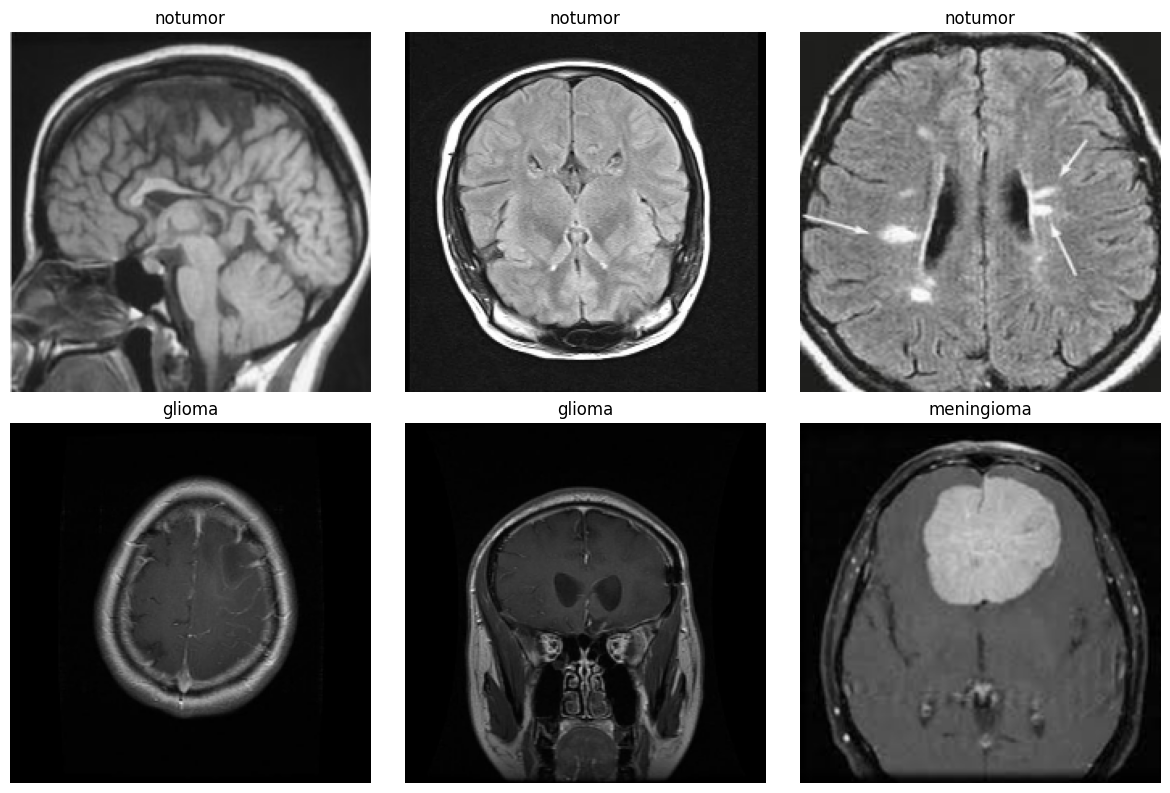

In [17]:
preview_images, preview_labels = next(iter(full_dataset))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, label in zip(
    axes.flat,
    preview_images[:6],
    preview_labels[:6],
):
    ax.imshow(image.numpy())
    ax.set_title(CLASSES[int(label.numpy())])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
print(full_dataset.element_spec)

(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


In [19]:
batch_images, batch_labels = next(iter(full_dataset))

print("Images shape:", batch_images.shape)
print("Images dtype:", batch_images.dtype)
print("Labels shape:", batch_labels.shape)
print("Labels dtype:", batch_labels.dtype)
print("Pixel range:", batch_images.numpy().min(), batch_images.numpy().max())
print("Labels in batch:", np.unique(batch_labels.numpy()))

Images shape: (32, 224, 224, 3)
Images dtype: <dtype: 'uint8'>
Labels shape: (32,)
Labels dtype: <dtype: 'int64'>
Pixel range: 0 255
Labels in batch: [0 1 2 3]


In [20]:
# Preserve the official partition: Tr-* for development and Te-* for final testing.
original_train_samples = [
    (path, label)
    for path, label in samples
    if Path(path).name.startswith("Tr-")
]

test_samples = [
    (path, label)
    for path, label in samples
    if Path(path).name.startswith("Te-")
]

# Fail early if any filename does not belong to one of the official partitions.
if len(original_train_samples) + len(test_samples) != len(samples):
    raise ValueError(
        "Some images do not start with Tr- or Te-; inspect their filenames before splitting."
    )

original_train_labels = [
    label
    for _, label in original_train_samples
]

# Create validation data only from official training images, keeping test images untouched.
train_samples, val_samples = train_test_split(
    original_train_samples,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=original_train_labels,
)

# Protect against path leakage between training, validation, and test partitions.
train_paths = {Path(path) for path, _ in train_samples}
val_paths = {Path(path) for path, _ in val_samples}
test_paths = {Path(path) for path, _ in test_samples}
assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

def print_class_counts(split_name, split_samples):
    # Convert numeric labels back to readable class names, then count them.
    counts = Counter(CLASSES[label] for _, label in split_samples)
    print(f"{split_name}: {len(split_samples)} images")
    for class_name in CLASSES:
        print(f"  {class_name}: {counts[class_name]}")


print_class_counts("Training", train_samples)  # Checks balance after duplicate removal.
print_class_counts("Validation", val_samples)  # Confirms stratification worked.
print_class_counts("Original test", test_samples)  # Documents the untouched holdout set.
print(
    "Total:",
    len(train_samples)
    + len(val_samples)
    + len(test_samples),
)


Training: 4625 images
  glioma: 1123
  meningioma: 1131
  notumor: 1147
  pituitary: 1224
Validation: 817 images
  glioma: 198
  meningioma: 200
  notumor: 203
  pituitary: 216
Original test: 1284 images
  glioma: 299
  meningioma: 304
  notumor: 381
  pituitary: 300
Total: 6726


In [21]:
# Build tf.data pipelines only after the final split lists have been created.
train_ds = make_dataset(
    train_samples,
    training=True,
)
val_ds = make_dataset(
    val_samples,
    training=False,
)
test_ds = make_dataset(
    test_samples,
    training=False,
)


In [22]:
def preprocess_for_mobilenet(images, labels):
    # MobileNetV2 expects float32 pixels scaled from [0, 255] to approximately [-1, 1].
    images = tf.cast(images, tf.float32)
    images = tf.keras.applications.mobilenet_v2.preprocess_input(images)

    return images, labels


# Inspect one raw batch before augmentation and preprocessing.
sample_images, sample_labels = next(iter(train_ds))
processed_images, processed_labels = preprocess_for_mobilenet(
    sample_images,
    sample_labels,
)


In [ ]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomRotation(
            factor=0.03,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
        tf.keras.layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=None,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
    ],
    name="mri_augmentation",
)

raw_images, raw_labels = next(iter(train_ds))

augmented_images = data_augmentation(
    raw_images,
    training=True,
)

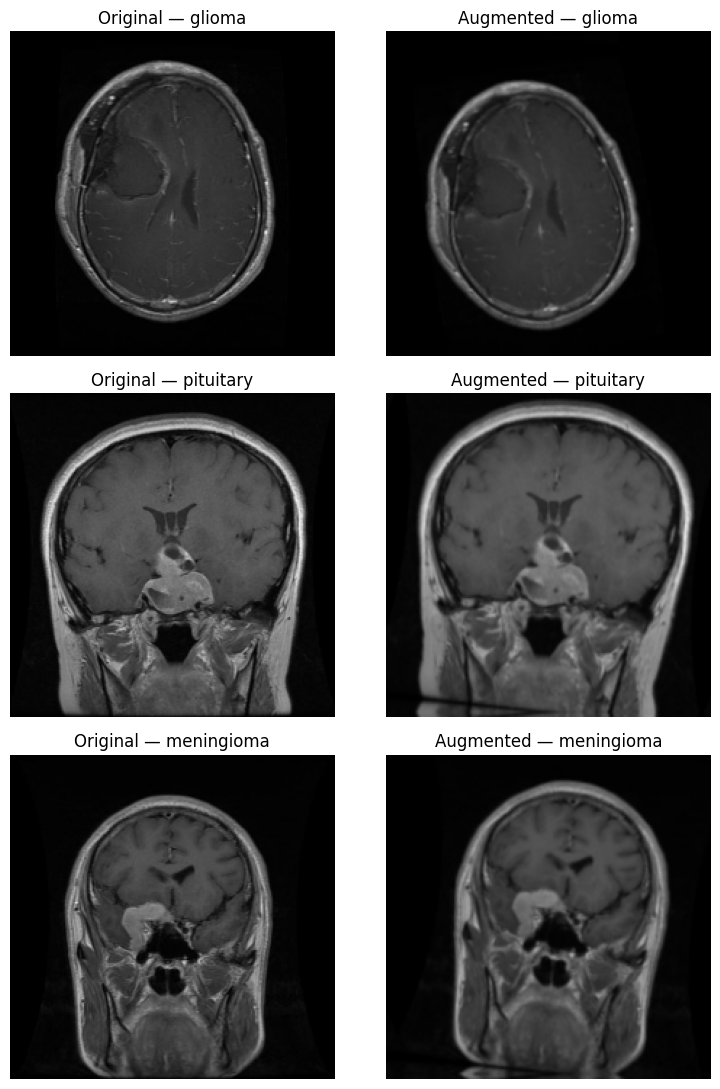

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(8, 11))

for row in range(3):
    label = int(raw_labels[row].numpy())

    axes[row, 0].imshow(raw_images[row].numpy())
    axes[row, 0].set_title(
        f"Original — {CLASSES[label]}"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        tf.cast(augmented_images[row], tf.uint8).numpy()
    )
    axes[row, 1].set_title(
        f"Augmented — {CLASSES[label]}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def prepare_for_mobilenet(dataset, augment=False):
    def transform(images, labels):
        # Apply random augmentation only to training batches.
        if augment:
            images = data_augmentation(
                images,
                training=True,
            )

        return preprocess_for_mobilenet(
            images,
            labels,
        )

    dataset = dataset.map(
        transform,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


# Build model-ready pipelines from the corrected official partitions.
train_model_ds = prepare_for_mobilenet(
    train_ds,
    augment=True,
)
val_model_ds = prepare_for_mobilenet(
    val_ds,
    augment=False,
)
test_model_ds = prepare_for_mobilenet(
    test_ds,
    augment=False,
)

# Confirm the expected image and batch counts before model training.
print(
    "Training:", len(train_samples), "images,",
    train_model_ds.cardinality().numpy(), "batches",
)
print(
    "Validation:", len(val_samples), "images,",
    val_model_ds.cardinality().numpy(), "batches",
)
print(
    "Test:", len(test_samples), "images,",
    test_model_ds.cardinality().numpy(), "batches",
)


Training: 4625 images, 145 batches
Validation: 817 images, 26 batches
Test: 1284 images, 41 batches


In [ ]:
def create_manifest_records(
    split_name,
    split_samples,
):
    records = []

    for path, label in split_samples:
        records.append(
            {
                "split": split_name,
                "path": str(
                    Path(path).relative_to(DATA_DIR)
                ),
                "label": int(label),
                "class_name": CLASSES[int(label)],
            }
        )

    return records


# Build the manifest only after the corrected split exists.
manifest_records = []

manifest_records.extend(
    create_manifest_records(
        "train",
        train_samples,
    )
)
manifest_records.extend(
    create_manifest_records(
        "validation",
        val_samples,
    )
)
manifest_records.extend(
    create_manifest_records(
        "test",
        test_samples,
    )
)

# Serialize with sorted keys so the same split always produces the same hash.
manifest_text = json.dumps(manifest_records, indent=2, sort_keys=True)
MANIFEST_PATH = ARTIFACT_DIR / "split_manifest.json"
MANIFEST_PATH.write_text(manifest_text, encoding="utf-8")  # Saves the exact split used by training.
SPLIT_MANIFEST_HASH = hashlib.sha256(manifest_text.encode("utf-8")).hexdigest()

print("Manifest saved to:", MANIFEST_PATH)
print("Manifest SHA-256:", SPLIT_MANIFEST_HASH)  # Equal hashes mean equal split records.

Manifest saved to: /workspace/neurovision_artifacts/split_manifest.json
Manifest SHA-256: 31ea3e12c5661f77bedbda356e0c342b9911f4685e4772bb4fec8fcfdd02ac77


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet", # load the image weight from the imagenet, insted of using random weight
    include_top=False, # remove the original ImageNet classifier (1,000), to be (4) classifiers
    input_shape=(*IMAGE_SIZE, 3), # defined the expected image shape
)

base_model.trainable = False # prevent training from medifiying the pretrained MobileNet2 weight || New classifier → weights are learned

In [ ]:
inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))

features = base_model(inputs, training=False)

pooled_features = tf.keras.layers.GlobalAveragePooling2D()(features)

In [ ]:
regularized_features = tf.keras.layers.Dropout(
    rate=0.2,
    seed=RANDOM_STATE
)(pooled_features)


In [ ]:
outputs = tf.keras.layers.Dense(
    units=len(CLASSES),
    activation="softmax",
    name="predictions"
)(regularized_features)

In [ ]:
model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="brain_tumor_mobilenetv2"
)

model.summary()

Model: "brain_tumor_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", # Track validation loss
    patience=5, # Allow 5 epochs without sufficient improvement
    min_delta=1e-4, # Require improvement greater than 0.0001
    restore_best_weights=True, # Restore the best model weights
    verbose=1 # Display callback messages
)

In [ ]:
reduce_learning_rate = tf.keras.callbacks.ReduceLROnPlateau( # Slow down learning when improvement stalls
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [ ]:
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),  # Portable checkpoint path for Kaggle and Vast.ai.
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

transfer_backup = tf.keras.callbacks.BackupAndRestore(
    backup_dir=str(ARTIFACT_DIR / "backup_transfer"),  # Stores temporary recovery state.
    delete_checkpoint=True,  # Removes the temporary backup after successful training.
)

In [ ]:
# Callbacks use validation data; the official test set remains untouched during training.
callbacks = [
    model_checkpoint,
    reduce_learning_rate,
    early_stopping,
    transfer_backup,  # Resumes the interrupted fit from the last completed epoch.
]

mlflow.tensorflow.autolog(log_models=False, checkpoint=False)  # Logs epochs but avoids duplicate model checkpoints.

with mlflow.start_run(run_name="mobilenetv2_transfer") as transfer_run:
    transfer_run_id = transfer_run.info.run_id  # Keeps the run ID for logging validation results later.
    mlflow.log_params({
        "stage": "transfer_learning",
        "backbone": "MobileNetV2",
        "learning_rate": 1e-3,
        "batch_size": BATCH_SIZE,
        "image_size": str(IMAGE_SIZE),
        "random_state": RANDOM_STATE,
        "split_manifest_hash": SPLIT_MANIFEST_HASH,
    })
    mlflow.log_artifact(str(MANIFEST_PATH), artifact_path="data")  # Attaches the exact split to the run.

    transfer_start = time.perf_counter()  # Starts a precise training timer.
    history = model.fit(
        train_model_ds,
        validation_data=val_model_ds,
        epochs=30,
        callbacks=callbacks,
        verbose=1,
    )
    transfer_duration = time.perf_counter() - transfer_start
    mlflow.log_metric("training_duration_seconds", transfer_duration)

print(f"Transfer-learning duration: {transfer_duration:.1f} seconds")


Epoch 1/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5814 - loss: 1.0248
Epoch 1: val_loss improved from inf to 0.46277, saving model to /workspace/neurovision_artifacts/best_mobilenetv2.keras
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 134ms/step - accuracy: 0.5823 - loss: 1.0227 - val_accuracy: 0.8262 - val_loss: 0.4628 - learning_rate: 0.0010
Epoch 2/30
144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.8484 - loss: 0.4037
Epoch 2: val_loss improved from 0.46277 to 0.45029, saving model to /workspace/neurovision_artifacts/best_mobilenetv2.keras
145/145 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - accuracy: 0.8485 - loss: 0.4036 - val_accuracy: 0.8286 - val_loss: 0.4503 - learning_rate: 0.0010
Epoch 3/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.8689 - loss: 0.3510
Epoch 3: val_loss did not improve from 0.45029
145/145 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.8689 - loss: 0.3509 - val_accuracy: 0.8384 - val_loss: 0.4561 - learning_rate: 0.0010
Epoch 4/30
144/145

2026/10/23 11:50:19 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: INVALID_PARAMETER_VALUE: Changing param values is not allowed. Params were already logged='[{'key': 'batch_size', 'old_value': '32', 'new_value': 'None'}]' for run ID='206b5af6014b4a0c8d817d302a2edbdc'.


🏃 View run mobilenetv2_transfer at: http://127.0.0.1:5000/#/experiments/1/runs/206b5af6014b4a0c8d817d302a2edbdc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Transfer-learning duration: 152.9 seconds


In [ ]:
# Reload the best validation checkpoint instead of assuming the final epoch is best.
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)


In [ ]:
transfer_validation_results = best_model.evaluate(
    val_model_ds,  # Compare candidates on validation data, not on the final test set.
    verbose=0,
    return_dict=True
)

print("Transfer validation results:", transfer_validation_results)
print(
    "Validation batches:",
    val_model_ds.cardinality().numpy()
)

Transfer validation results: {'accuracy': 0.8776009678840637, 'loss': 0.3120186924934387}
Validation batches: 26


In [ ]:
def calculate_validation_metrics(y_true, y_pred, evaluation_results):
    # output_dict=True gives us numeric values that MLflow can store directly.
    report = classification_report(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0,
    )

    metrics = {
        "validation_loss": float(evaluation_results["loss"]),
        "validation_accuracy": float(evaluation_results["accuracy"]),
        "validation_macro_f1": float(report["macro avg"]["f1-score"]),
    }

    for class_name in CLASSES:
        # Per-class recall is important because missed tumors are clinically sensitive.
        metrics[f"validation_recall_{class_name}"] = float(report[class_name]["recall"])

    return metrics, report


# Collect validation labels in the same deterministic order as predictions.
y_true_transfer_val = np.concatenate([
    labels.numpy()
    for _, labels in val_model_ds
])

transfer_val_probabilities = best_model.predict(
    val_model_ds,
    verbose=0
)

y_pred_transfer_val = np.argmax(
    transfer_val_probabilities,
    axis=1
)

transfer_val_metrics, transfer_val_report = calculate_validation_metrics(
    y_true_transfer_val,
    y_pred_transfer_val,
    transfer_validation_results,
)
transfer_val_matrix = confusion_matrix(
    y_true_transfer_val,
    y_pred_transfer_val,
    labels=range(len(CLASSES)),
)

with mlflow.start_run(run_id=transfer_run_id):
    mlflow.log_metrics(transfer_val_metrics)  # Adds macro-F1 and recalls to the transfer run.
    mlflow.log_dict(transfer_val_report, "metrics/validation_report.json")
    mlflow.log_dict({"matrix": transfer_val_matrix.tolist()}, "metrics/validation_confusion_matrix.json")
    mlflow.tensorflow.log_model(best_model, name="model")  # Logs the best saved checkpoint, not the last epoch.

print("Transfer validation metrics:", transfer_val_metrics)
print("Transfer validation confusion matrix:")
print(transfer_val_matrix)

2026/10/23 11:50:41 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run mobilenetv2_transfer at: http://127.0.0.1:5000/#/experiments/1/runs/206b5af6014b4a0c8d817d302a2edbdc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Transfer validation metrics: {'validation_loss': 0.3120186924934387, 'validation_accuracy': 0.8776009678840637, 'validation_macro_f1': 0.8771966095015793, 'validation_recall_glioma': 0.8838383838383839, 'validation_recall_meningioma': 0.775, 'validation_recall_notumor': 0.8916256157635468, 'validation_recall_pituitary': 0.9537037037037037}
Transfer validation confusion matrix:
[[175  17   0   6]
 [ 14 155   6  25]
 [  0  14 181   8]
 [  1   9   0 206]]


🏃 View run mobilenetv2_transfer at: http://127.0.0.1:5000/#/experiments/1/runs/206b5af6014b4a0c8d817d302a2edbdc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


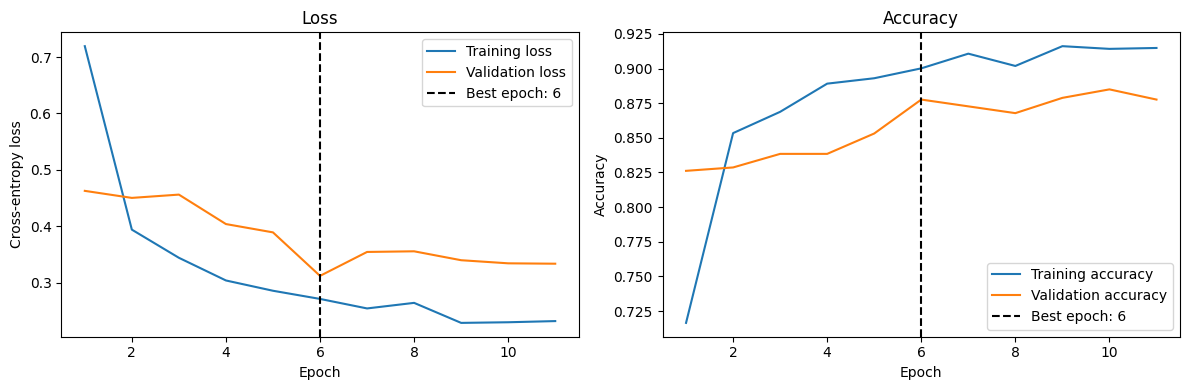

History keys: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])
Best validation-loss epoch: 6
Best validation loss: 0.3120186924934387
Validation accuracy at best epoch: 0.8776009678840637


In [ ]:
history_values = history.history
epochs = range(
    1,
    len(history_values["loss"]) + 1
)

best_epoch = (
    np.argmin(history_values["val_loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    epochs,
    history_values["loss"],
    label="Training loss"
)
axes[0].plot(
    epochs,
    history_values["val_loss"],
    label="Validation loss"
)
axes[0].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(
    epochs,
    history_values["accuracy"],
    label="Training accuracy"
)
axes[1].plot(
    epochs,
    history_values["val_accuracy"],
    label="Validation accuracy"
)
axes[1].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
with mlflow.start_run(run_id=transfer_run_id):
    mlflow.log_figure(fig, "plots/transfer_learning_curves.png")  # Keeps the graph beside its MLflow run.
plt.show()

print("History keys:", history_values.keys())
print("Best validation-loss epoch:", best_epoch)
print(
    "Best validation loss:",
    history_values["val_loss"][best_epoch - 1]
)
print(
    "Validation accuracy at best epoch:",
    history_values["val_accuracy"][best_epoch - 1]
)

In [ ]:
fine_tune_base = best_model.get_layer(
    "mobilenetv2_1.00_224"
)

# First allow individual MobileNetV2 layers to become trainable.
fine_tune_base.trainable = True

# Keep the earlier general-purpose feature layers frozen.
for layer in fine_tune_base.layers[:-20]:
    layer.trainable = False

# Preserve MobileNetV2's learned normalization statistics.
for layer in fine_tune_base.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

trainable_feature_layers = [
    layer.name
    for layer in fine_tune_base.layers
    if layer.trainable and layer.trainable_weights
]

trainable_parameter_count = sum(
    int(np.prod(weight.shape))
    for weight in best_model.trainable_weights
)

print(
    "Total MobileNetV2 layers:",
    len(fine_tune_base.layers)
)
print(
    "Trainable feature layers:",
    trainable_feature_layers
)
print(
    "Total trainable parameters:",
    trainable_parameter_count
)

Total MobileNetV2 layers: 154
Trainable feature layers: ['block_15_expand', 'block_15_depthwise', 'block_15_project', 'block_16_expand', 'block_16_depthwise', 'block_16_project', 'Conv_1']
Total trainable parameters: 1200004


In [ ]:
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

current_learning_rate = float(
    tf.keras.backend.get_value(
        best_model.optimizer.learning_rate
    )
)

print(
    "Fine-tuning learning rate:",
    current_learning_rate
)
print(
    "Trainable parameters:",
    sum(
        int(np.prod(weight.shape))
        for weight in best_model.trainable_weights
    )
)

Fine-tuning learning rate: 9.999999747378752e-06
Trainable parameters: 1200004


In [ ]:
FINE_TUNED_MODEL_PATH = (
    ARTIFACT_DIR
    / "best_mobilenetv2_finetuned.keras"
)

fine_tune_early_stopping = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    )
)

fine_tune_reduce_learning_rate = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
)

fine_tune_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(FINE_TUNED_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
)

fine_tune_backup = tf.keras.callbacks.BackupAndRestore(
    backup_dir=str(ARTIFACT_DIR / "backup_fine_tune"),  # Uses a separate recovery folder for this stage.
    delete_checkpoint=True,  # Cleans the temporary backup after a successful fit.
)

fine_tune_callbacks = [
    fine_tune_checkpoint,
    fine_tune_reduce_learning_rate,
    fine_tune_early_stopping,
    fine_tune_backup,  # Lets fine-tuning continue after an interruption.
]

print(
    "Fine-tuned checkpoint:",
    FINE_TUNED_MODEL_PATH
)
print(
    "Early-stopping patience:",
    fine_tune_early_stopping.patience
)
print(
    "Minimum learning rate:",
    fine_tune_reduce_learning_rate.min_lr
)

Fine-tuned checkpoint: /workspace/neurovision_artifacts/best_mobilenetv2_finetuned.keras
Early-stopping patience: 4
Minimum learning rate: 1e-07


In [ ]:
with mlflow.start_run(run_name="mobilenetv2_finetune") as fine_tune_run:
    fine_tune_run_id = fine_tune_run.info.run_id  # Keeps this run separate from transfer learning.
    mlflow.log_params({
        "stage": "fine_tuning",
        "backbone": "MobileNetV2",
        "learning_rate": 1e-5,
        "batch_size": BATCH_SIZE,
        "image_size": str(IMAGE_SIZE),
        "random_state": RANDOM_STATE,
        "trainable_feature_layers": len(trainable_feature_layers),
        "split_manifest_hash": SPLIT_MANIFEST_HASH,
        "source_transfer_run_id": transfer_run_id,
    })
    mlflow.log_artifact(str(MANIFEST_PATH), artifact_path="data")  # Proves both runs used the same split.

    fine_tune_start = time.perf_counter()  # Starts the fine-tuning timer.
    fine_tune_history = best_model.fit(
        train_model_ds,
        validation_data=val_model_ds,
        epochs=15,
        callbacks=fine_tune_callbacks,
        verbose=1
    )
    fine_tune_duration = time.perf_counter() - fine_tune_start
    mlflow.log_metric("training_duration_seconds", fine_tune_duration)

fine_tune_values = fine_tune_history.history

best_fine_tune_epoch = (
    np.argmin(fine_tune_values["val_loss"]) + 1
)

print(
    "Completed fine-tuning epochs:",
    len(fine_tune_values["loss"])
)
print(
    "Best fine-tuning epoch:",
    best_fine_tune_epoch
)
print(
    "Best fine-tuning validation loss:",
    fine_tune_values["val_loss"][
        best_fine_tune_epoch - 1
    ]
)
print(
    "Validation accuracy at that epoch:",
    fine_tune_values["val_accuracy"][
        best_fine_tune_epoch - 1
    ]
)
print(f"Fine-tuning duration: {fine_tune_duration:.1f} seconds")

Epoch 1/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9007 - loss: 0.2550
Epoch 1: val_loss improved from inf to 0.29086, saving model to /workspace/neurovision_artifacts/best_mobilenetv2_finetuned.keras
145/145 ━━━━━━━━━━━━━━━━━━━━ 35s 142ms/step - accuracy: 0.9007 - loss: 0.2550 - val_accuracy: 0.8849 - val_loss: 0.2909 - learning_rate: 1.0000e-05
Epoch 2/15
144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9153 - loss: 0.2359
Epoch 2: val_loss improved from 0.29086 to 0.28465, saving model to /workspace/neurovision_artifacts/best_mobilenetv2_finetuned.keras
145/145 ━━━━━━━━━━━━━━━━━━━━ 13s 81ms/step - accuracy: 0.9153 - loss: 0.2357 - val_accuracy: 0.8984 - val_loss: 0.2847 - learning_rate: 1.0000e-05
Epoch 3/15
144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9181 - loss: 0.2156
Epoch 3: val_loss did not improve from 0.28465
145/145 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step - accuracy: 0.9182 - loss: 0.2154 - val_accuracy: 0.8837 - val_loss: 0.3188 - learning_rat

2026/10/23 11:53:46 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: INVALID_PARAMETER_VALUE: Changing param values is not allowed. Params were already logged='[{'key': 'batch_size', 'old_value': '32', 'new_value': 'None'}]' for run ID='94d74f40d26349198325765014d9aa37'.


🏃 View run mobilenetv2_finetune at: http://127.0.0.1:5000/#/experiments/1/runs/94d74f40d26349198325765014d9aa37
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Completed fine-tuning epochs: 12
Best fine-tuning epoch: 8
Best fine-tuning validation loss: 0.24365781247615814
Validation accuracy at that epoch: 0.9033047556877136
Fine-tuning duration: 171.1 seconds


In [ ]:
saved_fine_tuned_model = (
    tf.keras.models.load_model(
        FINE_TUNED_MODEL_PATH
    )
)

fine_tune_validation_results = (
    saved_fine_tuned_model.evaluate(
        val_model_ds,
        verbose=0,
        return_dict=True
    )
)

print(
    "Checkpoint path:",
    FINE_TUNED_MODEL_PATH
)
print(
    "Saved checkpoint validation results:",
    fine_tune_validation_results
)

# Compute the same validation metrics so both MLflow runs are directly comparable.
y_true_fine_tune_val = np.concatenate([
    labels.numpy()
    for _, labels in val_model_ds
])
fine_tune_val_probabilities = saved_fine_tuned_model.predict(val_model_ds, verbose=0)
y_pred_fine_tune_val = np.argmax(fine_tune_val_probabilities, axis=1)

fine_tune_val_metrics, fine_tune_val_report = calculate_validation_metrics(
    y_true_fine_tune_val,
    y_pred_fine_tune_val,
    fine_tune_validation_results,
)
fine_tune_val_matrix = confusion_matrix(
    y_true_fine_tune_val,
    y_pred_fine_tune_val,
    labels=range(len(CLASSES)),
)

with mlflow.start_run(run_id=fine_tune_run_id):
    mlflow.log_metrics(fine_tune_val_metrics)  # Adds comparable metrics to the fine-tuning run.
    mlflow.log_dict(fine_tune_val_report, "metrics/validation_report.json")
    mlflow.log_dict({"matrix": fine_tune_val_matrix.tolist()}, "metrics/validation_confusion_matrix.json")
    mlflow.tensorflow.log_model(saved_fine_tuned_model, name="model")  # Logs the best fine-tuned checkpoint.

candidate_macro_f1 = {
    "mobilenetv2_transfer": transfer_val_metrics["validation_macro_f1"],
    "mobilenetv2_finetune": fine_tune_val_metrics["validation_macro_f1"],
}
selected_candidate = max(candidate_macro_f1, key=candidate_macro_f1.get)  # Selects using validation only.
print("Fine-tuning validation metrics:", fine_tune_val_metrics)
print("Selected candidate by validation macro-F1:", selected_candidate)

Checkpoint path: /workspace/neurovision_artifacts/best_mobilenetv2_finetuned.keras
Saved checkpoint validation results: {'accuracy': 0.9033047556877136, 'loss': 0.24365781247615814}


2026-10-23 11:53:58.379422: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026/10/23 11:54:08 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run mobilenetv2_finetune at: http://127.0.0.1:5000/#/experiments/1/runs/94d74f40d26349198325765014d9aa37
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Fine-tuning validation metrics: {'validation_loss': 0.24365781247615814, 'validation_accuracy': 0.9033047556877136, 'validation_macro_f1': 0.9037418654173649, 'validation_recall_glioma': 0.898989898989899, 'validation_recall_meningioma': 0.815, 'validation_recall_notumor': 0.9310344827586207, 'validation_recall_pituitary': 0.9629629629629629}
Selected candidate by validation macro-F1: mobilenetv2_finetune


In [ ]:
from mlflow import MlflowClient

MODEL_NAME = "NeuroVisionAI-MobileNetV2"
MODEL_URI = f"models:/{MODEL_NAME}@champion"
client = MlflowClient()
experiment = client.get_experiment_by_name(MLFLOW_EXPERIMENT)
if experiment is None:
    raise ValueError(f"Experiment not found: {MLFLOW_EXPERIMENT}")

runs = client.search_runs(
    [experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED' AND metrics.validation_macro_f1 >= 0",
    order_by=["metrics.validation_macro_f1 DESC"],
)  # Reads stored validation results, even after a notebook restart.
candidates = [
    run for run in runs
    if run.data.params.get("stage") in ("transfer_learning", "fine_tuning")
]
if not candidates:
    raise ValueError("No finished transfer or fine-tuning candidate was found.")
split_hashes = {run.data.params.get("split_manifest_hash") for run in candidates}
if len(split_hashes) != 1 or None in split_hashes:
    raise ValueError("Candidates used different data splits; compare one split at a time.")
winner_run = candidates[0]  # Highest validation macro-F1; test scores stay out of selection.
winner_run_id = winner_run.info.run_id
selected_candidate = (
    "mobilenetv2_finetune"
    if winner_run.data.params["stage"] == "fine_tuning"
    else "mobilenetv2_transfer"
)

logged_models = mlflow.search_logged_models(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"source_run_id = '{winner_run_id}'",
    output_format="list",
)  # Finds the model saved by the winning run.
if len(logged_models) != 1:
    raise ValueError(f"Expected one winning model, found {len(logged_models)}")

versions = client.search_model_versions(f"name = '{MODEL_NAME}'")
matching_versions = [item for item in versions if item.run_id == winner_run_id]
version = max(matching_versions, key=lambda item: int(item.version), default=None)
if version is None:
    version = mlflow.register_model(
        model_uri=f"models:/{logged_models[0].model_id}",
        name=MODEL_NAME,
    )  # Creates a version only if this run was not registered already.

client.set_registered_model_alias(MODEL_NAME, "champion", version.version)
print("Selected run:", winner_run_id, selected_candidate)
print("Validation macro-F1:", winner_run.data.metrics["validation_macro_f1"])
print("Champion:", MODEL_URI, "version:", version.version)

In [ ]:
# Test the exact registered champion selected by validation.
champion_model = mlflow.tensorflow.load_model(MODEL_URI)
champion_source_run_id = winner_run_id  # Tracks the model actually loaded above.

with mlflow.start_run(run_name="champion_final_test") as champion_test_run:
    champion_test_run_id = champion_test_run.info.run_id
    mlflow.set_tags({
        "selected_candidate": selected_candidate,
        "source_training_run_id": champion_source_run_id,
        "evaluation_split": "test",
    })
    champion_test_result = champion_model.evaluate(
        test_model_ds,  # This is the single final holdout evaluation stage.
        verbose=0,
        return_dict=True
    )
    mlflow.log_metrics({
        "test_loss": float(champion_test_result["loss"]),
        "test_accuracy": float(champion_test_result["accuracy"]),
    })

print("Champion:", selected_candidate)
print("Champion test results:", champion_test_result)
print("Test images:", len(test_samples))

In [ ]:
# Collect the true labels from every test batch.
y_true_champion = np.concatenate([
    labels.numpy()
    for _, labels in test_model_ds
])

# Predict one probability for each class.
y_prob_champion = champion_model.predict(
    test_model_ds,
    verbose=1
)

# Convert probabilities into predicted class numbers.
y_pred_champion = np.argmax(
    y_prob_champion,
    axis=1
)

print("True labels shape:", y_true_champion.shape)
print("Predicted labels shape:", y_pred_champion.shape)

champion_test_report = classification_report(
    y_true_champion,
    y_pred_champion,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)
champion_test_matrix = confusion_matrix(
    y_true_champion,
    y_pred_champion,
    labels=range(len(CLASSES)),
)

with mlflow.start_run(run_id=champion_test_run_id):
    mlflow.log_metrics({
        "test_macro_f1": float(champion_test_report["macro avg"]["f1-score"]),
        **{
            f"test_recall_{class_name}": float(champion_test_report[class_name]["recall"])
            for class_name in CLASSES
        },
    })
    mlflow.log_dict(champion_test_report, "metrics/test_classification_report.json")
    mlflow.log_dict({"matrix": champion_test_matrix.tolist()}, "metrics/test_confusion_matrix.json")

print("\nChampion classification report:")
print(classification_report(
    y_true_champion,
    y_pred_champion,
    labels=range(len(CLASSES)),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))
print("Champion confusion matrix:")
print(champion_test_matrix)

41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step
True labels shape: (1284,)
Predicted labels shape: (1284,)
🏃 View run champion_final_test at: http://127.0.0.1:5000/#/experiments/1/runs/cbdb98f55761464c9af45b714c642224
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

Champion classification report:
              precision    recall  f1-score   support

      glioma     0.9344    0.8094    0.8674       299
  meningioma     0.8020    0.7730    0.7873       304
     notumor     0.9599    0.9423    0.9510       381
   pituitary     0.8324    0.9933    0.9058       300

    accuracy                         0.8832      1284
   macro avg     0.8822    0.8795    0.8779      1284
weighted avg     0.8868    0.8832    0.8822      1284

Champion confusion matrix:
[[242  44   0  13]
 [ 13 235  15  41]
 [  3  13 359   6]
 [  1   1   0 298]]


Misclassified glioma images: 57


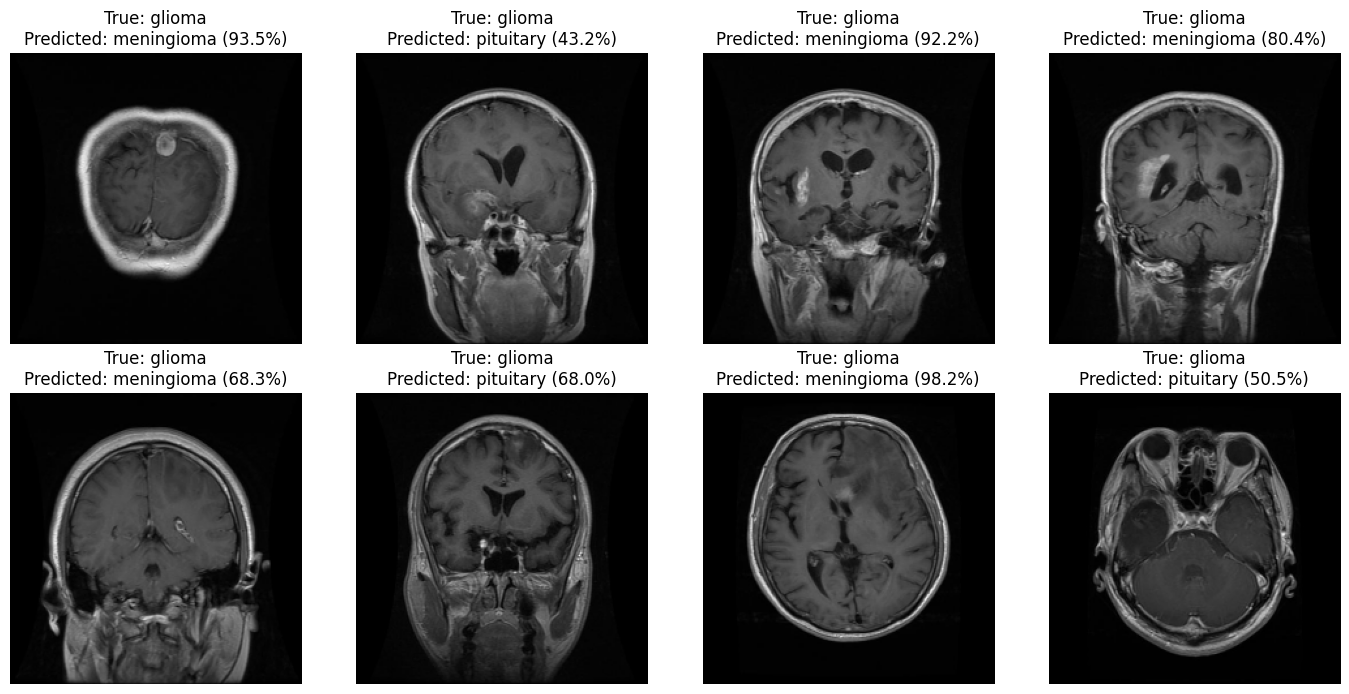

In [ ]:
# Find test images whose true class is glioma but whose prediction is different.
glioma_index = CLASSES.index("glioma")

glioma_error_indices = np.where(
    (y_true_champion == glioma_index) &
    (y_pred_champion != glioma_index)
)[0]

print("Misclassified glioma images:", len(glioma_error_indices))

# Display the first eight glioma errors.
selected_indices = glioma_error_indices[:8]

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

for axis, image_index in zip(axes.flat, selected_indices):
    image_path, _ = test_samples[image_index]
    image = load_image_opencv(image_path)

    predicted_index = y_pred_champion[image_index]
    predicted_class = CLASSES[predicted_index]
    confidence = y_prob_champion[
        image_index,
        predicted_index
    ]

    axis.imshow(image)
    axis.set_title(
        f"True: glioma\n"
        f"Predicted: {predicted_class} ({confidence:.1%})"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

**Error-analysis note:** The champion is selected with validation macro-F1 before the test cells run. After a clean execution, summarize the final test report shown above without using it to change hyperparameters or switch models.

In [ ]:
# Check one validation image through the same alias Streamlit will use.
registry_model = mlflow.tensorflow.load_model(MODEL_URI)
validation_images, validation_labels = next(iter(val_model_ds))
scores = registry_model.predict(validation_images[:1], verbose=0)[0]
print("True label:", CLASSES[int(validation_labels[0].numpy())])
print("Predicted label:", CLASSES[int(np.argmax(scores))])
print("Scores shape:", scores.shape)  # Four scores, one per class.